# Dự báo xu hướng bài hát thịnh hành trên Spotify
## Logistic: 10 đặc trưng âm thanh + 2 tín hiệu tuần đầu

**Câu hỏi nghiên cứu:** Khi một bài hát lần đầu được quan sát trên **Global Top 200**, dựa vào đặc trưng âm thanh, thứ hạng và lượt nghe tuần đó, có thể dự báo bài hát đạt **Global Top 50 ít nhất một lần trong 8 tuần tiếp theo** hay không?

- Một dòng cho mỗi bài hát, tại tuần đầu được quan sát trong bộ dữ liệu.
- **X:** đúng 12 biến, gồm 10 audio + `rank_first_week` + `log_streams_first_week`.
- **Y:** `hit_next_8_weeks`; không dùng `pop_score` hoặc popularity hiện tại.
- **Một thuật toán, một mô hình Logistic**; không dùng Random Forest hay mô hình phụ.
- Đọc `data/processed/charts_clean.parquet`, là bảng được notebook tiền xử lý xuất từ CSV gốc.
- Kết quả riêng trong `reports/global_top50_first_week/`; không ghi đè đầu vào hoặc kết quả bài toán đa thị trường.

**Phạm vi quan trọng:** bao gồm bài có hạng đầu 1–50 lẫn 51–200; không chỉ dự báo bứt phá từ hạng 51–200. Tuần đầu không được tính là thành công tương lai. Đây không phải dự báo bài chưa phát hành, cũng không phải dự báo chính xác thứ hạng từng tuần.

## 1. Khởi tạo môi trường

Notebook có toàn bộ code cần thiết, không phụ thuộc một module mô hình tự viết khác. Cần pandas, NumPy, scikit-learn, matplotlib, seaborn, joblib và engine Parquet như pyarrow. Các bước fit chỉ dùng Train; ngưỡng chỉ chọn trên Validation.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from scipy.special import expit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    precision_recall_curve, roc_curve, brier_score_loss,
)
from sklearn.calibration import calibration_curve

AUDIO_FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min',
]
FEATURES = AUDIO_FEATURES + ['rank_first_week', 'log_streams_first_week']
TARGET = 'hit_next_8_weeks'
HORIZON_WEEKS = 8
THRESHOLDS = np.round(np.linspace(0.10, 0.90, 81), 2)

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'notebooks').exists() and (p / 'src/data_loader.py').exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Hãy chạy notebook từ thư mục dự án hoặc notebooks.')
DATA_PATH = ROOT / 'data/processed/charts_clean.parquet'
OUT = ROOT / 'reports/global_top50_first_week'
OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12})

def show_and_save(fig, filename):
    fig.savefig(OUT / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('scikit-learn:', sklearn.__version__)
print('Nguồn:', DATA_PATH)
print('Thư mục kết quả:', OUT)
print('Số biến X:', len(FEATURES))

scikit-learn: 1.8.0
Nguồn: D:\ky1_nam3\Tương tác dữ liệu\project_ck\Spotify_Audio_Trends_Analytics\data\processed\charts_clean.parquet
Thư mục kết quả: D:\ky1_nam3\Tương tác dữ liệu\project_ck\Spotify_Audio_Trends_Analytics\reports\global_top50_first_week
Số biến X: 12


## 2. Nạp bảng Global và tạo dữ liệu tuần đầu

Luồng dữ liệu: **CSV gốc → tiền xử lý → charts_clean.parquet → bảng một dòng mỗi bài → Logistic**.

Chỉ lấy Global, không cộng/trộn lượt nghe của các quốc gia. Dòng lặp do một bài có nhiều nghệ sĩ được khử theo `(track_id, week)`; nếu rank, streams hoặc audio mâu thuẫn giữa các dòng trùng thì dừng để kiểm tra.

Tuần đầu là **lần đầu được quan sát trong dữ liệu hiện có**, chưa chắc là lần đầu trong toàn bộ lịch sử Spotify. Bài xuất hiện ngay tuần đầu bộ dữ liệu bị loại khỏi Train/Validation/Test vì không xác định được lần gia nhập thật.

In [2]:
def build_first_week_dataset(global_rows):
    required = [
        'track_id', 'chart_country', 'week', 'rank', 'streams', 'duration',
    ] + [c for c in AUDIO_FEATURES if c != 'duration_min']
    missing = sorted(set(required) - set(global_rows.columns))
    if missing:
        raise ValueError(f'Thiếu cột: {missing}')
    g = global_rows.copy()
    if not g.chart_country.astype(str).eq('Global').all():
        raise ValueError('Chỉ dùng Global trong thiết kế này.')
    g['week'] = pd.to_datetime(g.week)
    if g.empty or g[['track_id', 'week']].isna().any().any():
        raise ValueError('Dữ liệu rỗng hoặc thiếu khóa.')
    if not (g['rank'].between(1, 200) & g['rank'].eq(np.floor(g['rank']))).all():
        raise ValueError('Thứ hạng phải là số nguyên 1..200.')
    if not (np.isfinite(g.streams) & g.streams.ge(0)).all():
        raise ValueError('Lượt nghe phải hữu hạn và không âm.')
    if not (np.isfinite(g.duration) & g.duration.gt(0)).all():
        raise ValueError('Thời lượng phải hữu hạn, dương, đơn vị mili-giây.')
    numeric = ['rank', 'streams', 'duration'] + required[6:]
    conflicts = g.groupby(['track_id', 'week'])[numeric].nunique(dropna=False).gt(1).any(axis=1)
    if conflicts.any():
        raise ValueError(f'Có {int(conflicts.sum())} khóa trùng nhưng giá trị mâu thuẫn.')
    input_rows = len(g)
    g = g.drop_duplicates(['track_id', 'week']).sort_values(['week', 'track_id'])
    first_week, last_week = g.week.min(), g.week.max()
    if not ((g.week - first_week).dt.days % 7).eq(0).all():
        raise ValueError('Các bản ghi không cùng lịch tuần 7 ngày.')

    calendar = pd.date_range(first_week, last_week, freq='7D')
    quality = pd.DataFrame(index=calendar)
    quality.index.name = 'week'
    quality['observed_tracks'] = g.groupby('week').track_id.nunique().reindex(calendar, fill_value=0)
    quality['top50_ranks'] = (
        g.loc[g['rank'].between(1, 50)].groupby('week')['rank']
        .nunique().reindex(calendar, fill_value=0)
    )
    quality['has_complete_top50'] = quality.top50_ranks.eq(50)
    first = g.drop_duplicates('track_id', keep='first').copy().reset_index(drop=True)
    first['first_chart_week'] = first.week
    first['rank_first_week'] = first['rank']
    first['streams_first_week'] = first.streams
    first['log_streams_first_week'] = np.log1p(first.streams)
    first['duration_min'] = first.duration / 60000
    first['label_window_end'] = first.week + pd.Timedelta(weeks=HORIZON_WEEKS)
    rank_lookup = g.set_index(['track_id', 'week'])['rank']
    full_window = np.ones(len(first), dtype=bool)
    future_hit = np.zeros(len(first), dtype=bool)
    # Calendar lookups exclude t0 and avoid an all-history self-join.
    for k in range(1, HORIZON_WEEKS + 1):
        future = first[['track_id', 'week']].copy()
        future['week'] += pd.Timedelta(weeks=k)
        full_window &= (
            quality.has_complete_top50.reindex(future.week)
            .astype('boolean').fillna(False).to_numpy(dtype=bool)
        )
        ranks = rank_lookup.reindex(pd.MultiIndex.from_frame(future)).to_numpy()
        future_hit |= (ranks >= 1) & (ranks <= 50)
    first['has_valid_label'] = full_window
    first[TARGET] = pd.array(
        np.where(full_window, future_hit.astype(float), np.nan), dtype='Int8',
    )
    first['is_left_censored'] = first.week.eq(first_week)
    first['is_right_censored'] = first.label_window_end.gt(last_week)
    first['label_status'] = np.select(
        [first.is_right_censored, ~full_window],
        ['right_censored', 'incomplete_future_top50'], default='valid',
    )
    first['eligible_for_model'] = full_window & ~first.is_left_censored
    first[FEATURES] = first[FEATURES].replace([np.inf, -np.inf], np.nan)
    audit = {
        'input_global_rows': input_rows,
        'unique_track_week_rows': len(g), 'unique_tracks': len(first),
        'calendar_weeks': len(calendar),
        'complete_top50_weeks': int(quality.has_complete_top50.sum()),
        'missing_or_incomplete_top50_weeks': int((~quality.has_complete_top50).sum()),
        'source_start': str(first_week.date()), 'source_end': str(last_week.date()),
        'eligible_tracks_before_split_purge': int(first.eligible_for_model.sum()),
        'left_boundary_tracks_excluded': int(first.is_left_censored.sum()),
        'right_censored_tracks': int(first.is_right_censored.sum()),
        'unknown_labels': int(first[TARGET].isna().sum()),
    }
    return first, quality.reset_index(), audit

source_columns = [
    'track_id', 'track_name', 'artist_names', 'chart_country',
    'week', 'rank', 'streams', 'duration',
] + [c for c in AUDIO_FEATURES if c != 'duration_min']
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Chưa có {DATA_PATH}. Hãy chạy notebook tiền xử lý.')
global_raw = pd.read_parquet(
    DATA_PATH, columns=source_columns, filters=[('chart_country', '==', 'Global')],
)
first_week_data, chart_quality, audit = build_first_week_dataset(global_raw)
del global_raw
display(pd.DataFrame([audit]).T.rename(columns={0: 'value'}))
display(first_week_data[['track_id', 'track_name', 'first_chart_week',
                         'rank_first_week', 'streams_first_week', TARGET]].head())

,value
input_global_rows,95932
unique_track_week_rows,57993
unique_tracks,5347
calendar_weeks,290
complete_top50_weeks,287
missing_or_incomplete_top50_weeks,3
source_start,2016-12-29
source_end,2022-07-14
eligible_tracks_before_split_purge,4665
left_boundary_tracks_excluded,200


,track_id,track_name,first_chart_week,rank_first_week,streams_first_week,hit_next_8_weeks
0,02WacdrRpm4zlP8H7X6bnQ,Dancing On My Own,2016-12-29,148,3454666,0
1,04CttTezSnv71USiiG9mIo,Lighthouse - Andrelli Remix,2016-12-29,143,3500923,0
2,04DwTuZ2VBdJCCC5TROn7L,In the Name of Love,2016-12-29,16,12854288,1
3,08WPvDEsHvTFuB9w8tC2OS,Now and Later,2016-12-29,36,7724332,1
4,0ADG9OgdVTL7fgREP75BrZ,Ain't My Fault,2016-12-29,157,3315571,0


## 3. Định nghĩa nhãn Y và kiểm tra cửa sổ 8 tuần

\[
Y_i=\mathbb{1}\{\exists k\in\{1,\ldots,8\}:1\le rank_{i,t_0+k}\le50\}.
\]

- **Y = 1:** có ít nhất một lần đạt Global Top 50 ở tuần \(t_0+1\) đến \(t_0+8\).
- **Y = 0:** không đạt trong cửa sổ, với đủ tám bảng Top 50 hợp lệ.
- **Y = NA:** chưa hết cửa sổ hoặc thiếu bảng/thiếu hạng Top 50 ở bất kỳ tuần tương lai nào.

Chính sách bảo thủ giữ nhãn chưa xác định ngay cả khi thấy một sự kiện dương trong cửa sổ chưa đầy đủ. Bài vắng mặt ở một bảng Top 50 đầy đủ là không đạt Top 50 tuần đó; bảng bị thiếu dữ liệu không phải bằng chứng Y = 0.

Để xác định sự kiện Top 50, cần đủ hạng **1–50**, không bắt buộc đủ 200 hạng. Dữ liệu sạch có thể đã loại dòng ở bước trước; kiểm tra này không phục hồi các dòng đã mất.

**Ví dụ:** bài ở hạng 20 tuần đầu nhưng cả tám tuần sau đều ngoài Top 50 vẫn có Y = 0. Bài ở hạng 120 tuần đầu và đạt hạng 42 tuần thứ ba có Y = 1.

In [3]:
display(first_week_data.groupby(['label_status', 'is_left_censored'], observed=True)
        .agg(tracks=('track_id', 'size'), known_labels=(TARGET, 'count'),
             positives=(TARGET, 'sum')))
eligible = first_week_data.loc[first_week_data.eligible_for_model]
display(eligible[TARGET].value_counts().rename_axis('Y').to_frame('tracks'))
print('Tỷ lệ Y=1 của nhóm đủ điều kiện:', f'{eligible[TARGET].astype(int).mean():.2%}')
display(chart_quality.loc[~chart_quality.has_complete_top50])
assert first_week_data.track_id.is_unique
assert first_week_data.loc[~first_week_data.has_valid_label, TARGET].isna().all()
assert set(eligible[TARGET].astype(int).unique()) == {0, 1}

Tỷ lệ Y=1 của nhóm đủ điều kiện: 22.87%


tracks  known_labels  positives
label_status            is_left_censored                                 
incomplete_future_top50 False                364             0          0
right_censored          False                118             0          0
valid                   False               4665          4665       1067
                        True                 200           200         57

,tracks
Y,
0,3598
1,1067


,week,observed_tracks,top50_ranks,has_complete_top50
29,2017-07-20,196,46,False
45,2017-11-09,199,49,False
241,2021-08-12,199,49,False


## 4. Chia Train / Validation / Test theo thời gian

Khởi đầu bằng tỷ lệ xấp xỉ **60% / 20% / 20%** theo số bài đủ điều kiện, sắp theo tuần đầu. Bài cùng tuần luôn ở cùng một phân vùng, không chia ngẫu nhiên.

- Train: học trung vị, StandardScaler và hệ số Logistic.
- Validation: chọn ngưỡng F1 trên lưới đã định trước.
- Test: đánh giá sau khi khóa ngưỡng.

**Loại chồng lấn nhãn:** chỉ giữ Train nếu toàn bộ cửa sổ 8 tuần kết thúc trước mốc Validation; tương tự cho Validation trước Test. Vì vậy tỷ lệ cuối không còn đúng 60/20/20.

So sánh ngày tuần là mô phỏng theo lịch; chưa có timestamp công bố thực tế. Khoảng đệm không chứng minh mọi thông tin đều sẵn có đúng thời điểm dự báo.

In [4]:
def assign_temporal_splits(first):
    d = first.copy()
    eligible = d.loc[d.eligible_for_model]
    if eligible.empty:
        raise ValueError('Không có mẫu đủ điều kiện.')
    # Snap quantile boundaries to observed weeks so a week is never split.
    val_quantile = eligible.first_chart_week.quantile(0.60)
    test_quantile = eligible.first_chart_week.quantile(0.80)
    val_start = eligible.loc[eligible.first_chart_week.ge(val_quantile), 'first_chart_week'].min()
    test_start = eligible.loc[eligible.first_chart_week.ge(test_quantile), 'first_chart_week'].min()
    if not val_start < test_start:
        raise ValueError('Không đủ mốc tuần riêng cho Validation và Test.')
    e = d.eligible_for_model
    train_anchor = e & d.first_chart_week.lt(val_start)
    val_anchor = e & d.first_chart_week.ge(val_start) & d.first_chart_week.lt(test_start)
    test_anchor = e & d.first_chart_week.ge(test_start)
    train = train_anchor & d.label_window_end.lt(val_start)
    validation = val_anchor & d.label_window_end.lt(test_start)
    d['split_group'] = np.select(
        [d.is_left_censored, ~d.has_valid_label, train, validation, test_anchor,
         train_anchor & ~train, val_anchor & ~validation],
        ['excluded_left_boundary', 'unlabeled', 'train', 'validation', 'test',
         'purged_train_boundary', 'purged_validation_boundary'],
        default='excluded',
    )
    for name in ['train', 'validation', 'test']:
        if not d.split_group.eq(name).any():
            raise ValueError(f'Tập {name} rỗng; cần thiết kế lại mốc chia.')
    assert d.loc[train, 'label_window_end'].max() < val_start
    assert d.loc[validation, 'label_window_end'].max() < test_start
    split_info = {
        'validation_start': str(val_start.date()), 'test_start': str(test_start.date()),
        'quantiles_before_purge': [0.60, 0.80],
        'purged_tracks': int((train_anchor & ~train).sum() + (val_anchor & ~validation).sum()),
        'publication_timestamps_verified': False,
    }
    return d, split_info

first_week_data, split_info = assign_temporal_splits(first_week_data)
train = first_week_data.loc[first_week_data.split_group.eq('train')].copy()
validation = first_week_data.loc[first_week_data.split_group.eq('validation')].copy()
test = first_week_data.loc[first_week_data.split_group.eq('test')].copy()
for name, frame in [('train', train), ('validation', validation), ('test', test)]:
    if frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} phải có cả hai lớp để đánh giá.')

split_summary = first_week_data.groupby('split_group', observed=True).agg(
    tracks=('track_id', 'size'), start=('first_chart_week', 'min'),
    end=('first_chart_week', 'max'), positives=(TARGET, 'sum'),
)
split_summary['positive_rate'] = first_week_data.groupby('split_group', observed=True)[TARGET].mean()
display(split_summary)
display(pd.DataFrame([split_info]))
assert set(train.track_id).isdisjoint(validation.track_id)
assert set(train.track_id).isdisjoint(test.track_id)
assert set(validation.track_id).isdisjoint(test.track_id)

,tracks,start,end,positives,positive_rate
split_group,,,,,
excluded_left_boundary,200,2016-12-29,2016-12-29,57,0.285
purged_train_boundary,173,2020-01-09,2020-02-27,30,0.17341
purged_validation_boundary,86,2021-01-14,2021-03-04,20,0.232558
test,941,2021-03-11,2022-05-19,214,0.227418
train,2625,2017-01-05,2020-01-02,622,0.236952
unlabeled,482,2017-05-25,2022-07-14,0,<NA>
validation,840,2020-03-05,2021-01-07,181,0.215476


,validation_start,test_start,quantiles_before_purge,purged_tracks,publication_timestamps_verified
0,2020-03-05,2021-03-11,"[0.6, 0.8]",259,False


## 5. Đặc trưng X, tương quan và đa cộng tuyến

**10 audio:** danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, duration_min.

**2 tín hiệu tuần đầu:**

1. `rank_first_week`: hạng nhỏ hơn là vị trí tốt hơn.
2. `log_streams_first_week = ln(1 + streams_first_week)`: nén thang lượt nghe, không phải popularity chính thức và không phải tín hiệu độc lập với lượt nghe gốc.

Không đưa lượt nghe gốc vào cạnh log lượt nghe như biến thứ 13. Không dùng tổng streams, peak rank hoặc số tuần của toàn bộ tương lai.

Chỉ kiểm tra tương quan/VIF trên **Train**. Cột hằng bị loại khỏi phép chẩn đoán; nếu ma trận không đủ hạng thì không đưa VIF hữu hạn giả tạo. Đây không phải bước chọn/bỏ biến theo Test.

Thiếu dữ liệu Train theo biến:


,count,mean,std,min,25%,50%,75%,max
danceability,2625.0,0.685743,0.139974,0.153000,0.601000,0.700000,0.785000,0.974000
energy,2625.0,0.633539,0.166116,0.027900,0.534000,0.649000,0.756000,0.978000
loudness,2625.0,-6.330866,2.594023,-34.474998,-7.464000,-5.943000,-4.673000,0.175000
speechiness,2625.0,0.134289,0.123024,0.023200,0.045800,0.082300,0.186000,0.966000
acousticness,2625.0,0.225714,0.237803,0.000031,0.044100,0.137000,0.325000,0.993000
instrumentalness,2625.0,0.009827,0.062085,0.000000,0.000000,0.000000,0.000020,0.918000
liveness,2625.0,0.177957,0.134797,0.019700,0.097200,0.124000,0.212000,0.955000
valence,2625.0,0.477527,0.219100,0.037000,0.307000,0.471000,0.645000,0.982000
tempo,2625.0,121.614082,30.278973,54.747002,96.492996,119.930000,142.048004,212.117004
duration_min,2625.0,3.419870,0.774182,0.587333,2.956517,3.363133,3.801867,9.619984


,missing
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0
tempo,0
duration_min,0


,feature,vif,correlation_matrix_full_rank
10,rank_first_week,6.125013,True
11,log_streams_first_week,6.116022,True
1,energy,2.796879,True
2,loudness,2.366418,True
4,acousticness,1.523263,True
7,valence,1.354012,True
0,danceability,1.272282,True
3,speechiness,1.115638,True
8,tempo,1.057981,True
5,instrumentalness,1.049555,True


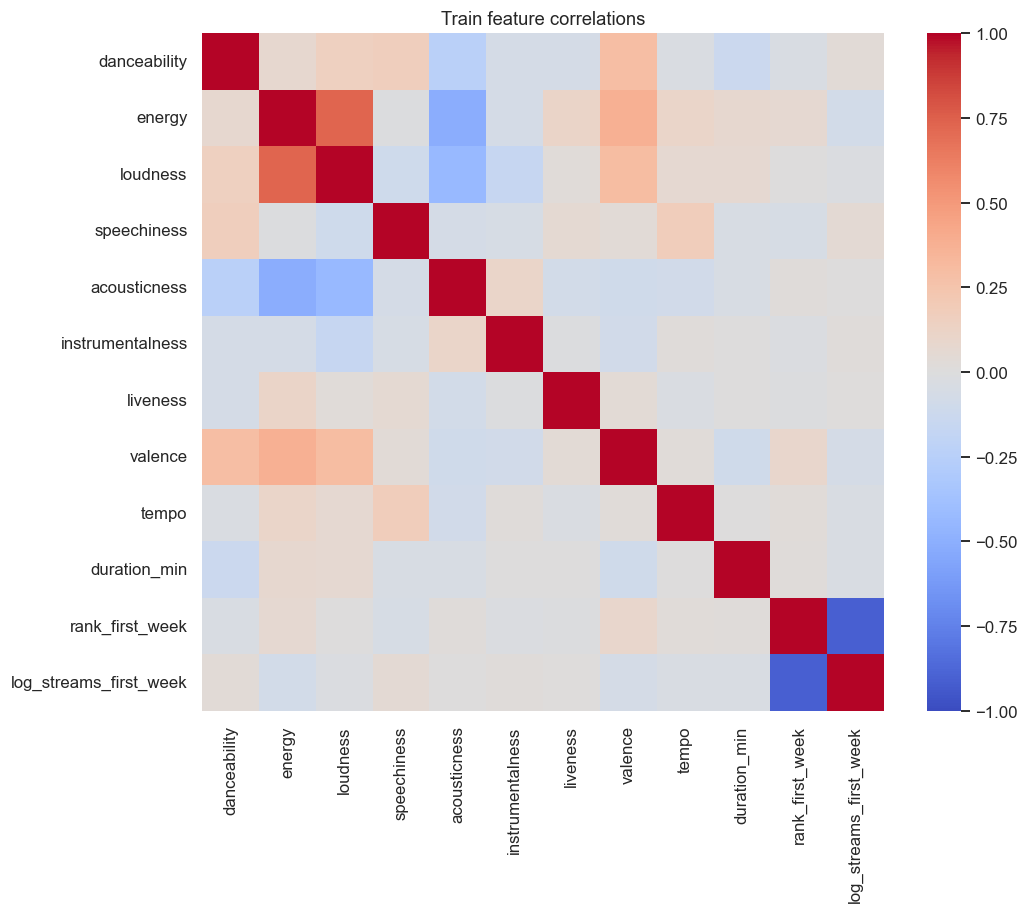

In [5]:
X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_validation, y_validation = validation[FEATURES], validation[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)
display(X_train.describe().T)
print('Thiếu dữ liệu Train theo biến:')
display(X_train.isna().sum().to_frame('missing'))
diagnostic = X_train.fillna(X_train.median()).dropna(axis=1)
diagnostic = diagnostic.loc[:, diagnostic.std() > 1e-10]
corr = diagnostic.corr()
full_rank = np.linalg.matrix_rank(corr.to_numpy()) == len(corr)
vif_table = pd.DataFrame({
    'feature': corr.columns,
    'vif': np.diag(np.linalg.inv(corr.to_numpy())) if full_rank else np.nan,
    'correlation_matrix_full_rank': full_rank,
})
display(vif_table.sort_values('vif', ascending=False))
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Train feature correlations')
show_and_save(fig, 'train_correlations.png')

## 6. Huấn luyện một mô hình hồi quy Logistic

\[
z=\beta_0+\sum_{j=1}^{12}\beta_j\widetilde X_j,\qquad
\hat p=\frac{1}{1+e^{-z}}.
\]

Pipeline: **median imputer → StandardScaler → Logistic Regression**. Tất cả được fit trên Train. Không thêm cờ thiếu để giữ đúng 12 biến đầu vào.

Cấu hình cố định giống lần thử nghiệm: `C=1`, regularization L2 mặc định, `class_weight='balanced'`, `solver='lbfgs'`, `max_iter=1000`, `random_state=42`.

Class weight thay đổi hàm mục tiêu, không bảo đảm tăng F1 và có thể làm điểm lệch xác suất thực tế. Vì vậy gọi \(\hat p\) là **điểm dự báo Logistic** cho đến khi kiểm chứng hiệu chỉnh. Không fit lại trên Train + Validation trước khi đánh giá Test.

In [6]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        C=1.0, class_weight='balanced', solver='lbfgs',
        max_iter=1000, random_state=42,
    )),
])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ConvergenceWarning)
    model.fit(X_train, y_train)
if any(issubclass(item.category, ConvergenceWarning) for item in caught):
    raise RuntimeError('Logistic chưa hội tụ. Cần xử lý trước khi báo cáo.')
print('Số vòng lặp:', int(model.named_steps['classifier'].n_iter_[0]))
assert model.named_steps['classifier'].coef_.shape == (1, 12)
p_validation = model.predict_proba(X_validation)[:, 1]

Số vòng lặp: 13


## 7. Chọn ngưỡng trên Validation

\[
\widehat Y_i=\mathbb{1}\{\widehat p_i\ge\tau\}.
\]

Ngưỡng \(\tau\) đặt lên **điểm Logistic**, không đặt riêng lên rank hoặc streams. Quét 81 ngưỡng từ 0.10 đến 0.90, chọn F1 cao nhất; nếu hòa thì ưu tiên Precision, sau đó ngưỡng cao hơn. Đây là tối ưu trên lưới định trước, không phải tối ưu trên mọi số thực.

AP và ROC-AUC đánh giá điểm xếp hạng, không dùng một ngưỡng để tính chúng. AP không đồng nhất với diện tích PR nội suy hình thang. Sau bước này khóa mô hình/ngưỡng trước khi chấm Test.

Ngưỡng đã khóa từ Validation: 0.79


,samples,positives,prevalence,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,tn,fp,fn,tp
0,840,181,0.215476,0.79,0.838095,0.645161,0.552486,0.595238,0.802379,0.625574,0.209986,604,55,81,100


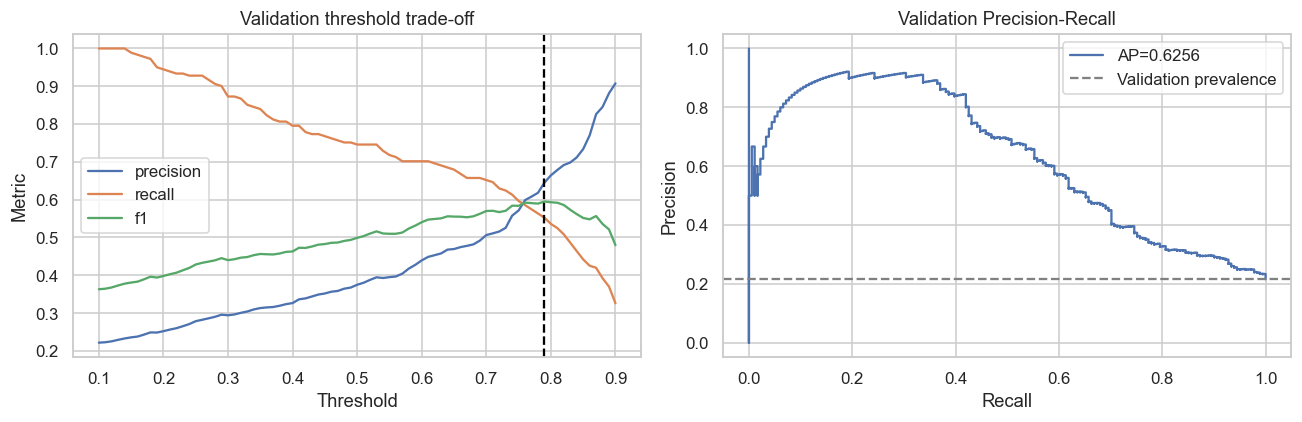

In [7]:
def classification_metrics(y, probabilities, threshold):
    y = np.asarray(y, dtype=int)
    p = np.asarray(probabilities, dtype=float)
    if len(y) == 0 or len(y) != len(p) or not np.isin(y, [0, 1]).all():
        raise ValueError('Cần nhãn nhị phân và điểm cùng độ dài, không rỗng.')
    if not (np.isfinite(p) & (p >= 0) & (p <= 1)).all():
        raise ValueError('Điểm phải hữu hạn trong [0, 1].')
    if not 0 <= threshold <= 1:
        raise ValueError('Ngưỡng phải trong [0, 1].')
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both_classes = np.unique(y).size == 2
    return {
        'samples': len(y), 'positives': int(y.sum()), 'prevalence': float(y.mean()),
        'threshold': float(threshold), 'accuracy': float(accuracy_score(y, pred)),
        'precision': float(precision_score(y, pred, zero_division=0)),
        'recall': float(recall_score(y, pred, zero_division=0)),
        'f1': float(f1_score(y, pred, zero_division=0)),
        'roc_auc': float(roc_auc_score(y, p)) if both_classes else np.nan,
        'average_precision': float(average_precision_score(y, p)) if both_classes else np.nan,
        'brier_score': float(brier_score_loss(y, p)),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

def validation_threshold_curve(y, probabilities):
    rows = []
    for threshold in THRESHOLDS:
        pred = np.asarray(probabilities) >= threshold
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        rows.append({
            'threshold': float(threshold),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0),
            'f1': f1_score(y, pred, zero_division=0),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        })
    return pd.DataFrame(rows)

threshold_curve = validation_threshold_curve(y_validation, p_validation)
best = threshold_curve.sort_values(
    ['f1', 'precision', 'threshold'], ascending=False, kind='stable',
).iloc[0]
selected_threshold = float(best.threshold)
validation_metrics = classification_metrics(y_validation, p_validation, selected_threshold)
display(pd.DataFrame([validation_metrics]))
print('Ngưỡng đã khóa từ Validation:', selected_threshold)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric in ['precision', 'recall', 'f1']:
    axes[0].plot(threshold_curve.threshold, threshold_curve[metric], label=metric)
axes[0].axvline(selected_threshold, color='black', linestyle='--')
axes[0].set(xlabel='Threshold', ylabel='Metric', title='Validation threshold trade-off')
axes[0].legend()
precision, recall, _ = precision_recall_curve(y_validation, p_validation)
axes[1].step(recall, precision, where='post', label=f"AP={validation_metrics['average_precision']:.4f}")
axes[1].axhline(y_validation.mean(), color='gray', linestyle='--', label='Validation prevalence')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Validation Precision-Recall')
axes[1].legend()
fig.tight_layout()
show_and_save(fig, 'validation_threshold_selection.png')

## 8. Đánh giá Test độc lập

Từ đây mới tính điểm Test. Ngưỡng không được chỉnh lại để làm đẹp kết quả.

- Precision: trong các bài dự đoán đạt Top 50, tỷ lệ thực sự đạt.
- Recall: trong các bài thực sự đạt, tỷ lệ mô hình phát hiện được.
- F1: trung bình điều hòa Precision và Recall.
- ROC-AUC: khả năng phân biệt/xếp hạng, không phải tỷ lệ dự đoán đúng.
- AP: đối chiếu với tỷ lệ Y=1 trên Test.
- Accuracy: đối chiếu với mốc luôn đoán lớp phổ biến.
- Brier/reliability: kiểm tra điểm có khớp tỷ lệ xảy ra hay không; **không học bộ hiệu chỉnh từ Test**.

Nhóm này bao gồm bài đã ở Top 50 tuần đầu. Không so trực tiếp các chỉ số với bài toán đa thị trường chỉ lấy hạng 51–200.

,split,model,samples,positives,prevalence,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,tn,fp,fn,tp
0,validation,Logistic_12_features,840,181,0.215476,0.79,0.838095,0.645161,0.552486,0.595238,0.802379,0.625574,0.209986,604,55,81,100
1,test,Logistic_12_features,941,214,0.227418,0.79,0.837407,0.656410,0.598131,0.625917,0.810738,0.690313,0.217278,660,67,86,128
2,test,Constant_Train_prevalence,941,214,0.227418,0.50,0.772582,0.000000,0.000000,0.000000,0.500000,0.227418,0.175790,727,0,214,0


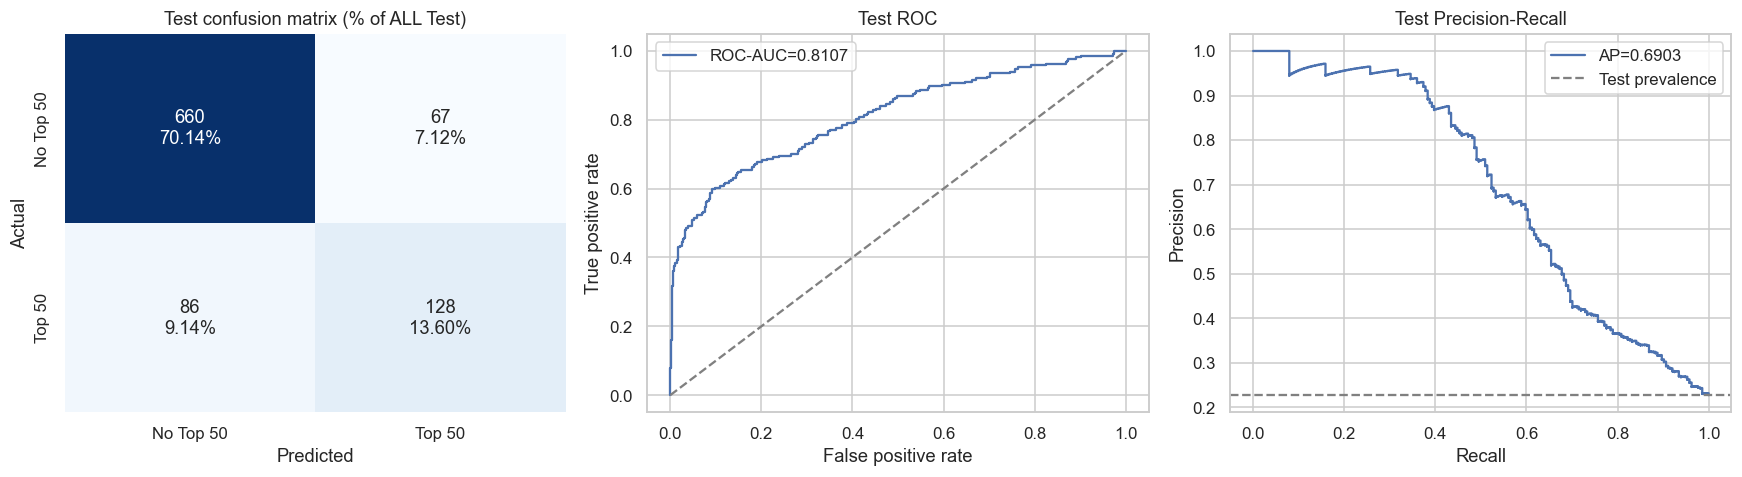

**Phần trăm trên ma trận tính trên toàn bộ Test**, không phải theo từng lớp. Recall = TP/(TP+FN); Precision = TP/(TP+FP).

In [8]:
p_test = model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= selected_threshold).astype(int)
test_metrics = classification_metrics(y_test, p_test, selected_threshold)
train_prior = float(y_train.mean())
constant_probability = np.full(len(y_test), train_prior)
baseline_threshold = 0.5
baseline_metrics = classification_metrics(y_test, constant_probability, baseline_threshold)
metrics_table = pd.DataFrame([
    {'split': 'validation', 'model': 'Logistic_12_features', **validation_metrics},
    {'split': 'test', 'model': 'Logistic_12_features', **test_metrics},
    {'split': 'test', 'model': 'Constant_Train_prevalence', **baseline_metrics},
])
display(metrics_table)
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
annotations = np.array([[f'{v:,}\n{v / cm.sum():.2%}' for v in row] for row in cm])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Top 50', 'Top 50'], yticklabels=['No Top 50', 'Top 50'])
axes[0].set(xlabel='Predicted', ylabel='Actual', title='Test confusion matrix (% of ALL Test)')
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f"ROC-AUC={test_metrics['roc_auc']:.4f}")
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC')
axes[1].legend()
precision, recall, _ = precision_recall_curve(y_test, p_test)
axes[2].step(recall, precision, where='post', label=f"AP={test_metrics['average_precision']:.4f}")
axes[2].axhline(y_test.mean(), color='gray', linestyle='--', label='Test prevalence')
axes[2].set(xlabel='Recall', ylabel='Precision', title='Test Precision-Recall')
axes[2].legend()
fig.tight_layout()
show_and_save(fig, 'test_evaluation.png')
display(Markdown(
    '**Phần trăm trên ma trận tính trên toàn bộ Test**, không phải theo từng lớp. '
    'Recall = TP/(TP+FN); Precision = TP/(TP+FP).'
))

### 8.1. Phân rã theo vị trí tuần đầu và kiểm tra hiệu chỉnh

Hai nhóm dưới đây là **đánh giá phụ sau khi khóa mô hình**, không dùng chọn mô hình hoặc ngưỡng:

- Hạng đầu 1–50: dự báo có ít nhất một lần tiếp tục/quay lại Top 50 trong tám tuần sau; không phải duy trì liên tục tám tuần.
- Hạng đầu 51–200: dự báo vào Top 50 trong tám tuần sau.

Cùng một mô hình được áp dụng cho cả hai. Kết quả chung không tự chứng minh tốt riêng cho nhóm bứt phá.

,entry_group,samples,positives,prevalence,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,tn,fp,fn,tp
0,first_rank_1_50,282,145,0.514184,0.79,0.702128,0.65641,0.882759,0.752941,0.81933,0.854827,0.312169,70,67,17,128
1,first_rank_51_200,659,69,0.104704,0.79,0.895296,0.00000,0.000000,0.000000,0.60027,0.140984,0.176673,590,0,69,0


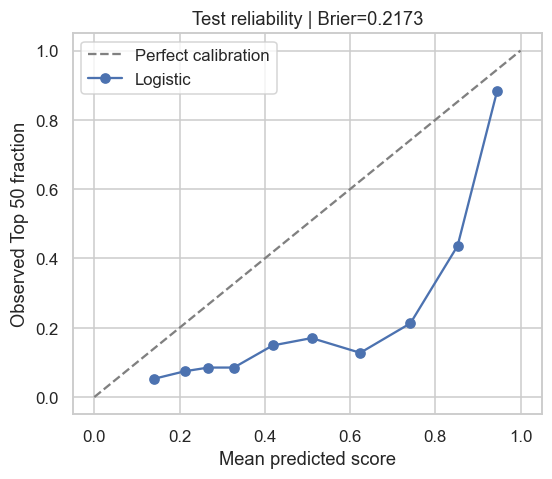

In [9]:
test_predictions = test[['track_id', 'track_name', 'first_chart_week',
                         'rank_first_week', 'streams_first_week', TARGET]].copy()
test_predictions['p_hat'] = p_test
test_predictions['predicted_class'] = pred_test
test_predictions['entry_group'] = np.where(
    test_predictions.rank_first_week.le(50), 'first_rank_1_50', 'first_rank_51_200',
)
subgroup_rows = []
for group_name, group in test_predictions.groupby('entry_group'):
    subgroup_rows.append({
        'entry_group': group_name,
        **classification_metrics(group[TARGET], group.p_hat, selected_threshold),
    })
subgroup_metrics = pd.DataFrame(subgroup_rows)
display(subgroup_metrics)
observed, predicted = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
reliability = pd.DataFrame({'mean_score': predicted, 'observed_fraction': observed})
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
ax.plot(predicted, observed, 'o-', label='Logistic')
ax.set(xlabel='Mean predicted score', ylabel='Observed Top 50 fraction',
       title=f"Test reliability | Brier={test_metrics['brier_score']:.4f}")
ax.legend()
show_and_save(fig, 'test_reliability.png')

## 9. Diễn giải hệ số, Odds Ratio và ví dụ tính điểm

Với biến đã chuẩn hóa, tăng **một độ lệch chuẩn Train**, giữ các biến khác cố định, làm odds mô hình ước lượng nhân với \(e^{\beta_j}\). Odds tăng 20% không đồng nghĩa xác suất tăng 20 điểm phần trăm.

Hệ số là mối liên hệ có điều kiện, không chứng minh nhân quả. Rank nhỏ tốt hơn nên dấu hệ số phải diễn giải theo chiều này. Các biến tương quan có thể làm hệ số nhạy với tập biến.

Không gắn p-value/CI của một Logit khác vào Logistic có regularization và class weight đang dùng. Notebook không huấn luyện mô hình thống kê phụ để tránh lẫn kết quả.

,feature,coefficient,odds_ratio,odds_change_percent,unit
11,log_streams_first_week,0.985122,2.678138,167.813830,+1 Train standard deviation after median imput...
0,danceability,0.185479,1.203795,20.379454,+1 Train standard deviation after median imput...
7,valence,0.138997,1.149120,14.912013,+1 Train standard deviation after median imput...
2,loudness,0.093691,1.098220,9.822028,+1 Train standard deviation after median imput...
9,duration_min,0.072805,1.075520,7.552042,+1 Train standard deviation after median imput...
1,energy,0.046019,1.047095,4.709464,+1 Train standard deviation after median imput...
4,acousticness,0.037529,1.038242,3.824166,+1 Train standard deviation after median imput...
8,tempo,0.025205,1.025525,2.552486,+1 Train standard deviation after median imput...
5,instrumentalness,-0.037084,0.963595,-3.640474,+1 Train standard deviation after median imput...
6,liveness,-0.078335,0.924655,-7.534519,+1 Train standard deviation after median imput...


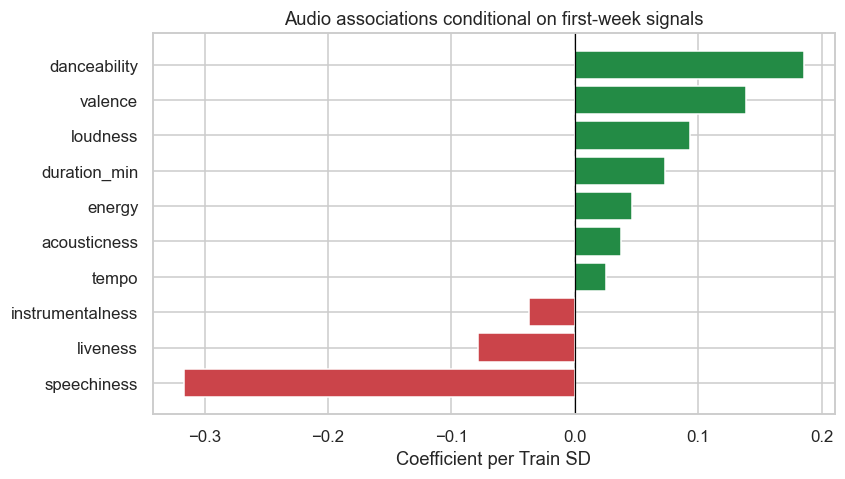

,track_name,first_chart_week,rank_first_week,streams_first_week,hit_next_8_weeks
5010,Cigarettes,2022-02-10,27,13042876,0


,feature,raw_value,standardized_value,coefficient,contribution_to_z
0,danceability,0.597000,-0.634121,0.185479,-0.117616
1,energy,0.615000,-0.111626,0.046019,-0.005137
2,loudness,-6.346000,-0.005835,0.093691,-0.000547
3,speechiness,0.042100,-0.749502,-0.316874,0.237498
4,acousticness,0.030300,-0.821905,0.037529,-0.030845
5,instrumentalness,0.000000,-0.158311,-0.037084,0.005871
6,liveness,0.378000,1.484315,-0.078335,-0.116273
7,valence,0.467000,-0.048055,0.138997,-0.006679
8,tempo,160.014008,1.268446,0.025205,0.031971
9,duration_min,3.792117,0.480917,0.072805,0.035013


**Intercept = -0.4628; z = 1.3177; điểm = 0.7888; ngưỡng = 0.79; dự đoán Y = 0.** Các hệ số trên được học từ Train, không phải hệ số đặt tay.

In [10]:
classifier = model.named_steps['classifier']
coefficients = pd.DataFrame({
    'feature': FEATURES, 'coefficient': classifier.coef_[0],
    'odds_ratio': np.exp(classifier.coef_[0]),
})
coefficients['odds_change_percent'] = (coefficients.odds_ratio - 1) * 100
coefficients['unit'] = '+1 Train standard deviation after median imputation'
display(coefficients.sort_values('coefficient', ascending=False))
audio_coefficients = coefficients.loc[coefficients.feature.isin(AUDIO_FEATURES)]
fig, ax = plt.subplots(figsize=(8, 4.5))
ordered = audio_coefficients.sort_values('coefficient')
ax.barh(ordered.feature, ordered.coefficient,
        color=np.where(ordered.coefficient >= 0, '#238b45', '#cb444a'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Coefficient per Train SD', title='Audio associations conditional on first-week signals')
show_and_save(fig, 'audio_coefficients.png')

example_position = int(np.argmin(np.abs(p_test - selected_threshold)))
example = test.iloc[[example_position]]
imputed = model.named_steps['imputer'].transform(example[FEATURES])
standardized = model.named_steps['scaler'].transform(imputed)[0]
contributions = pd.DataFrame({
    'feature': FEATURES, 'raw_value': example[FEATURES].iloc[0].to_numpy(),
    'standardized_value': standardized, 'coefficient': classifier.coef_[0],
})
contributions['contribution_to_z'] = contributions.standardized_value * contributions.coefficient
z_example = float(classifier.intercept_[0] + contributions.contribution_to_z.sum())
p_example = float(expit(z_example))
assert np.isclose(p_example, p_test[example_position])
display(example[['track_name', 'first_chart_week', 'rank_first_week',
                 'streams_first_week', TARGET]])
display(contributions)
display(Markdown(
    f"**Intercept = {classifier.intercept_[0]:.4f}; z = {z_example:.4f}; "
    f"điểm = {p_example:.4f}; ngưỡng = {selected_threshold:.2f}; "
    f"dự đoán Y = {int(p_example >= selected_threshold)}.** "
    'Các hệ số trên được học từ Train, không phải hệ số đặt tay.'
))

## 10. Dự báo từ thông tin tuần đầu và xuất dữ liệu Tableau

**Phần dự báo** gồm hai bước: `model.predict_proba(X)` trả điểm cho sự kiện tám tuần sau; so điểm với `selected_threshold` để trả dự đoán 0/1.

Hàm dưới đây nhận đúng 10 audio và hai tín hiệu của một tuần đầu đã được công bố. Nó không dự báo được bài chưa có rank/streams, không tự biết ngày phát hành hoặc thứ hạng tương lai.

Các bài chưa hết tám tuần ở cuối dữ liệu có thể được chấm điểm, nhưng Y/residual để trống. Đây là **các bài lịch sử cuối bộ dữ liệu**, không phải dữ liệu Spotify trực tiếp hiện tại.

In [11]:
def forecast_first_week(audio_features, rank_first_week, streams_first_week,
                        fitted_model, threshold):
    missing = sorted(set(AUDIO_FEATURES) - set(audio_features))
    if missing:
        raise ValueError(f'Thiếu audio: {missing}')
    if not np.isfinite(rank_first_week) or not 1 <= rank_first_week <= 200 or int(rank_first_week) != rank_first_week:
        raise ValueError('Hạng đầu phải là số nguyên 1..200.')
    if not np.isfinite(streams_first_week) or streams_first_week < 0:
        raise ValueError('Streams đầu phải hữu hạn và không âm.')
    if not 0 <= threshold <= 1:
        raise ValueError('Ngưỡng phải trong [0, 1].')
    row = {key: float(audio_features[key]) for key in AUDIO_FEATURES}
    if not all(np.isfinite(value) for value in row.values()) or row['duration_min'] <= 0:
        raise ValueError('Audio phải hữu hạn; duration_min phải dương.')
    row['rank_first_week'] = rank_first_week
    row['log_streams_first_week'] = np.log1p(streams_first_week)
    x = pd.DataFrame([row], columns=FEATURES)
    score = float(fitted_model.predict_proba(x)[0, 1])
    return {
        'score': score, 'threshold': float(threshold),
        'predicted_class': int(score >= threshold),
        'event': 'Global Top 50 at least once in calendar weeks t0+1..t0+8',
    }

sample = example.iloc[0]
demo = forecast_first_week(
    sample[AUDIO_FEATURES].to_dict(), sample.rank_first_week,
    sample.streams_first_week, model, selected_threshold,
)
display(pd.DataFrame([demo]))
assert np.isclose(demo['score'], p_example)

scored = first_week_data.copy()
scoring_mask = ~scored.is_left_censored
scored['p_hat'] = np.nan
scored['logit_z'] = np.nan
scored.loc[scoring_mask, 'p_hat'] = model.predict_proba(scored.loc[scoring_mask, FEATURES])[:, 1]
scored.loc[scoring_mask, 'logit_z'] = model.decision_function(scored.loc[scoring_mask, FEATURES])
scored['threshold'] = selected_threshold
scored['predicted_class'] = pd.array(
    np.where(scored.p_hat.notna(), scored.p_hat.ge(selected_threshold), np.nan), dtype='Int8',
)
scored['residual'] = scored[TARGET].astype(float) - scored.p_hat
scored['confusion_category'] = pd.Series(pd.NA, index=scored.index, dtype='string')
known = scored[TARGET].notna() & scored.predicted_class.notna()
actual = scored.loc[known, TARGET].astype(int)
predicted_class = scored.loc[known, 'predicted_class'].astype(int)
scored.loc[known, 'confusion_category'] = np.select(
    [actual.eq(1) & predicted_class.eq(1),
     actual.eq(0) & predicted_class.eq(1),
     actual.eq(1) & predicted_class.eq(0)],
    ['TP', 'FP', 'FN'], default='TN',
)
scored['score_context'] = np.select(
    [scored.is_left_censored, scored.split_group.eq('train'),
     scored.split_group.eq('validation'), scored.split_group.eq('test'),
     scored.is_right_censored],
    ['not_scored_left_boundary', 'in_sample', 'validation_selection',
     'held_out_test', 'historical_pending_horizon'],
    default='purged_or_incomplete_chart_not_evaluation',
)
np.testing.assert_allclose(scored.loc[test.index, 'p_hat'], p_test)
assert scored.loc[scored[TARGET].isna(), 'residual'].isna().all()
display(scored.loc[scored.is_right_censored & ~scored.is_left_censored,
                   ['track_name', 'first_chart_week', 'p_hat', 'predicted_class', TARGET]].head())

,score,threshold,predicted_class,event
0,0.788803,0.79,0,Global Top 50 at least once in calendar weeks ...


,track_name,first_chart_week,p_hat,predicted_class,hit_next_8_weeks
5229,Satellite,2022-05-26,0.932444,1,<NA>
5230,Love Of My Life,2022-05-26,0.919642,1,<NA>
5231,Late Night Talking,2022-05-26,0.986252,1,<NA>
5232,Keep Driving,2022-05-26,0.909015,1,<NA>
5233,Balanço da Rede,2022-05-26,0.382120,0,<NA>


### 10.1. Các tệp kết quả

- `tableau_predictions.csv`: định danh, tuần đầu, 12 X, Y, tập dữ liệu, điểm, ngưỡng, dự đoán và loại lỗi.
- `tableau_metrics.csv`: kết quả Validation, Test và mốc hằng đơn giản.
- `tableau_threshold_validation.csv`: 81 ngưỡng **chỉ trên Validation**.
- `tableau_entry_group_metrics.csv`: Test theo nhóm hạng đầu 1–50 và 51–200.
- `tableau_coefficients.csv`, `tableau_reliability.csv`: giải thích hệ số và kiểm tra hiệu chỉnh.
- `first_week_forecast.parquet`, `selected_logistic.joblib`, `model_metrics.json`: dữ liệu dự báo, pipeline và cấu hình lần chạy.

Tableau lọc `split_group = test` để xem đánh giá độc lập; điểm Train là in-sample. Không kéo ngưỡng trên Test rồi coi kết quả đó là đánh giá độc lập ban đầu. Chỉ nạp joblib từ nguồn tin cậy.

In [12]:
export_columns = [
    'track_id', 'track_name', 'artist_names', 'first_chart_week',
    'streams_first_week', 'label_window_end', 'split_group',
    'has_valid_label', 'is_left_censored', 'is_right_censored',
    'label_status', 'eligible_for_model', TARGET,
] + FEATURES + [
    'p_hat', 'logit_z', 'threshold', 'predicted_class', 'residual',
    'confusion_category', 'score_context',
]
forecast_table = scored[export_columns]
forecast_table.to_csv(OUT / 'tableau_predictions.csv', index=False, encoding='utf-8-sig')
forecast_table.to_parquet(OUT / 'first_week_forecast.parquet', index=False, compression='snappy')
metrics_table.to_csv(OUT / 'tableau_metrics.csv', index=False, encoding='utf-8-sig')
threshold_curve.to_csv(OUT / 'tableau_threshold_validation.csv', index=False, encoding='utf-8-sig')
subgroup_metrics.to_csv(OUT / 'tableau_entry_group_metrics.csv', index=False, encoding='utf-8-sig')
coefficients.to_csv(OUT / 'tableau_coefficients.csv', index=False, encoding='utf-8-sig')
contributions.to_csv(OUT / 'tableau_example_contributions.csv', index=False, encoding='utf-8-sig')
reliability.to_csv(OUT / 'tableau_reliability.csv', index=False, encoding='utf-8-sig')
vif_table.to_csv(OUT / 'tableau_train_vif.csv', index=False, encoding='utf-8-sig')
split_summary.to_csv(OUT / 'tableau_split_summary.csv', encoding='utf-8-sig')
chart_quality.to_csv(OUT / 'tableau_chart_quality.csv', index=False, encoding='utf-8-sig')

metadata = {
    'task': 'Global Top 50 at least once in the next eight calendar weeks after first observation',
    'source': str(DATA_PATH.relative_to(ROOT)), 'grain': 'one row per track_id',
    'features': FEATURES, 'threshold': selected_threshold,
    'class_weight': 'balanced', 'C': 1.0, 'sklearn_version': sklearn.__version__,
    'data_audit': audit, 'split_info': split_info,
    'validation_metrics': validation_metrics, 'test_metrics': test_metrics,
    'threshold_grid': THRESHOLDS.tolist(),
    'probabilities_calibrated': False,
    'limitations': [
        'First observed week is not verified first-ever chart entry',
        'All first ranks 1..200 included, not breakthrough-only',
        'Historical audio availability and chart publication timestamps unverified',
        'Incomplete future Top 50 charts excluded rather than recovered',
        'Old historical data does not guarantee current performance',
    ],
}
(OUT / 'model_metrics.json').write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
)
joblib.dump({
    'pipeline': model, 'features': FEATURES, 'threshold': selected_threshold,
    'horizon_weeks': HORIZON_WEEKS, 'metadata': metadata,
}, OUT / 'selected_logistic.joblib', compress=3)
loaded = joblib.load(OUT / 'selected_logistic.joblib')
np.testing.assert_allclose(loaded['pipeline'].predict_proba(X_test)[:, 1], p_test)
print('Đã xuất kết quả riêng tại:', OUT)
display(pd.DataFrame([
    {'file': p.name, 'size_mb': round(p.stat().st_size / 1024**2, 3)}
    for p in sorted(OUT.iterdir()) if p.is_file()
]))

Đã xuất kết quả riêng tại: D:\ky1_nam3\Tương tác dữ liệu\project_ck\Spotify_Audio_Trends_Analytics\reports\global_top50_first_week


,file,size_mb
0,audio_coefficients.png,0.046
1,first_week_forecast.parquet,0.649
2,model_metrics.json,0.003
3,selected_logistic.joblib,0.003
4,tableau_chart_quality.csv,0.007
5,tableau_coefficients.csv,0.001
6,tableau_entry_group_metrics.csv,0.000
7,tableau_example_contributions.csv,0.001
8,tableau_metrics.csv,0.001
9,tableau_predictions.csv,1.543


## 11. Kết luận, giới hạn và liên kết báo cáo

Các con số bên dưới được tính từ lần chạy hiện tại, không điền trước để đạt một kết quả mong muốn.

**Giới hạn cần đưa vào báo cáo:**

1. Chỉ đại diện bài từng xuất hiện Global Top 200, không phải toàn bộ bài Spotify hoặc bài chưa phát hành.
2. Có bài đã ở Top 50 tuần đầu; cần đọc thêm kết quả riêng hạng đầu 51–200, không gọi toàn bộ là dự báo bứt phá.
3. Lần đầu được quan sát chưa chắc là lần đầu vào bảng thật. Loại mốc đầu bộ dữ liệu chỉ giảm vấn đề này, không giải quyết hoàn toàn.
4. Nguồn đã qua tiền xử lý; biểu đồ chất lượng không khôi phục dòng bị mất. Chính sách đủ tám bảng Top 50 loại thêm mẫu và có thể tạo thiên lệch chọn mẫu.
5. Chưa xác minh timestamp audio và công bố bảng tuần. Rank/streams chỉ được dùng sau khi tuần đầu được công bố.
6. Class weight có thể làm điểm chưa khớp xác suất thực tế. Reliability/Brier là kiểm tra, không phải bộ hiệu chỉnh.
7. Đánh giá một lần chia theo thời gian chưa chứng minh ổn định ở mọi giai đoạn; các cửa sổ tương lai của nhiều bài vẫn có thể chịu chung biến động thị trường.
8. Audio và hệ số chỉ thể hiện liên hệ có điều kiện, chưa đo quảng bá, nền tảng khác hoặc quan hệ nhân quả.
9. Dữ liệu kết thúc năm 2022; tập chưa đủ horizon là mô phỏng lịch sử, không phải kết quả Spotify trực tiếp hiện tại.
10. `04_story.ipynb` và dashboard cũ không được tự sửa trong yêu cầu này; khi làm báo cáo phải dùng đúng nhãn/kết quả mới, không lấy chỉ số `pop_score >= 50`.

In [13]:
m = test_metrics
breakthrough = subgroup_metrics.loc[subgroup_metrics.entry_group.eq('first_rank_51_200')]
if not breakthrough.empty:
    b = breakthrough.iloc[0]
    display(Markdown(
        f"### Lưu ý riêng cho bài bắt đầu ở hạng 51–200\n\n"
        f"Ở ngưỡng đã khóa **{selected_threshold:.2f}**, phát hiện **{int(b.tp)}/{int(b.positives)}** "
        f"bài thực sự đạt Top 50; Precision **{b.precision:.2%}**, Recall **{b.recall:.2%}**, "
        f"F1 **{b.f1:.2%}**, ROC-AUC **{b.roc_auc:.4f}**.\n\n"
        "**Kết quả chung không thể thay cho khả năng dự báo bứt phá của nhóm này.** "
        "Không đổi ngưỡng dựa trên kết quả Test vừa quan sát."
    ))
    if int(b.tp) == 0 and int(b.positives) > 0:
        display(Markdown(
            "**Cảnh báo: mô hình bỏ sót toàn bộ bài thành công trong nhóm hạng đầu 51–200 "
            "ở ngưỡng hiện tại. Các dự đoán đúng lớp 1 trong Test đều thuộc nhóm đã ở Top 50 tuần đầu.**"
        ))
if test_metrics['brier_score'] > baseline_metrics['brier_score']:
    display(Markdown(
        f"**Điểm chưa được hiệu chỉnh tốt:** Brier của Logistic "
        f"**{test_metrics['brier_score']:.4f}** cao hơn mốc điểm hằng "
        f"**{baseline_metrics['brier_score']:.4f}** (thấp hơn tốt hơn). "
        "Không trình bày điểm Logistic như xác suất thành công đã được kiểm chứng."
    ))
ap_lift = m['average_precision'] / m['prevalence']
precision_gap = 1 - m['precision']
display(Markdown(
    f"### Kết quả mô hình 12 biến\n\n"
    f"- **Train: {len(train):,}; Validation: {len(validation):,}; Test: {len(test):,} bài.**\n"
    f"- Ngưỡng chọn trên Validation: **{selected_threshold:.2f}**.\n"
    f"- Precision **{m['precision']:.2%}**; Recall **{m['recall']:.2%}**; F1 **{m['f1']:.2%}**.\n"
    f"- Accuracy **{m['accuracy']:.2%}**; ROC-AUC **{m['roc_auc']:.4f}**; AP **{m['average_precision']:.4f}**.\n"
    f"- AP bằng **{ap_lift:.2f} lần** mốc tỷ lệ dương Test **{m['prevalence']:.2%}**; "
    "đây không phải tăng xác suất thành công từng bài cùng tỷ lệ đó.\n"
    f"- Bắt đúng **{m['tp']:,}** bài, báo nhầm **{m['fp']:,}**, bỏ sót **{m['fn']:,}**.\n\n"
    f"Trong những bài được dự đoán đạt Top 50, vẫn có **{precision_gap:.2%}** không đạt trong cửa sổ. "
    "Mô hình có giá trị sàng lọc trong phạm vi đã kiểm tra, không bảo đảm thành công. "
    "**Không so trực tiếp với kết quả bài toán đa thị trường hạng 51–200.**"
))

### Lưu ý riêng cho bài bắt đầu ở hạng 51–200

Ở ngưỡng đã khóa **0.79**, phát hiện **0/69** bài thực sự đạt Top 50; Precision **0.00%**, Recall **0.00%**, F1 **0.00%**, ROC-AUC **0.6003**.

**Kết quả chung không thể thay cho khả năng dự báo bứt phá của nhóm này.** Không đổi ngưỡng dựa trên kết quả Test vừa quan sát.

**Cảnh báo: mô hình bỏ sót toàn bộ bài thành công trong nhóm hạng đầu 51–200 ở ngưỡng hiện tại. Các dự đoán đúng lớp 1 trong Test đều thuộc nhóm đã ở Top 50 tuần đầu.**

**Điểm chưa được hiệu chỉnh tốt:** Brier của Logistic **0.2173** cao hơn mốc điểm hằng **0.1758** (thấp hơn tốt hơn). Không trình bày điểm Logistic như xác suất thành công đã được kiểm chứng.

### Kết quả mô hình 12 biến

- **Train: 2,625; Validation: 840; Test: 941 bài.**
- Ngưỡng chọn trên Validation: **0.79**.
- Precision **65.64%**; Recall **59.81%**; F1 **62.59%**.
- Accuracy **83.74%**; ROC-AUC **0.8107**; AP **0.6903**.
- AP bằng **3.04 lần** mốc tỷ lệ dương Test **22.74%**; đây không phải tăng xác suất thành công từng bài cùng tỷ lệ đó.
- Bắt đúng **128** bài, báo nhầm **67**, bỏ sót **86**.

Trong những bài được dự đoán đạt Top 50, vẫn có **34.36%** không đạt trong cửa sổ. Mô hình có giá trị sàng lọc trong phạm vi đã kiểm tra, không bảo đảm thành công. **Không so trực tiếp với kết quả bài toán đa thị trường hạng 51–200.**